### La biodiversité est-elle valorisée par les marchés financiers ? Une analyse économétrique et prédictive du S&P 500 (2000-2025)

**Données :** SP500 (Stooq) ; facteurs Fama-French (Kenneth French Data Library) ; indice d'attention à la biodiversité (NLP sur la presse américaine)
## Étapes
- Étape 1 : Chargement et exploration des données (2000-2025)
- Étape 2 : Sélection du modèle (comparaison de 4 modèles, choix de l'OLS)
- Étape 3 : Effet de la biodiversité sur la prime de risque (FF5 vs FF5 + biodiversité)
- Étape 4 : Robustesse sur sous-périodes (2000-2009, 2010-2019, 2020-2025)
- Étape 5 : Effet sur le risque extrême (VaR, Expected Shortfall et régression quantile)
- Étape 6 : Analyse autour de la COP15 (avant / après, test d'interaction, test placebo)


La biodiversité occupe une place de plus en plus importante dans les débats environnementaux et économiques. Face à la dégradation des écosystèmes, à la disparition de certaines espèces et aux conséquences du changement climatique, sa préservation est devenue un enjeu majeur pour l’ensemble de la société. Mais ces préoccupations ont-elles réellement un impact sur les marchés financiers ? Pour mieux comprendre ce lien, ce projet s’appuie sur les données du S&P 500 entre 2000 et 2025 afin d’étudier l’influence de l’attention portée à la biodiversité sur les rendements boursiers et les risques de pertes, notamment en période de crise.

In [1]:
# Importation des librairies
import warnings
warnings.filterwarnings('ignore', message='Pandas requires version')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.stattools import adfuller
from statsmodels.iolib.summary2 import summary_col
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

1-CHARGEMENT DES DONNÉES

Données de biodiversité et Fama-French

In [2]:
df_biodiv_FF = pd.read_excel("Données/BIODIV_Global_&_FF.xlsx")

In [3]:
df_biodiv_FF.head()

,date,Mkt-RF,SMB,HML,RMW,CMA,RF,Mom,Biodiv_Global
0,2000-01-04,-4.06,0.34,2.07,0.53,1.36,0.02,-1.91,-0.362485
1,2000-01-05,-0.09,0.36,-0.05,0.45,1.15,0.02,-0.49,-0.908798
2,2000-01-06,-0.74,-0.04,1.24,0.64,1.21,0.02,-1.49,0.026969
3,2000-01-11,-1.71,0.33,0.91,0.90,1.20,0.02,-1.17,0.236814
4,2000-01-12,-0.69,-0.22,0.74,0.42,0.85,0.02,-0.63,0.029222


In [4]:
# Dimensions du dataset 
print(df_biodiv_FF.shape)

(4020, 9)


 Chargement des données du SP500 et changement du format de date (SP_500)

In [5]:
SP_500 = pd.read_csv("Données/SP500_New.csv", sep=';')
SP_500.columns = ['date', 'SP500']
SP_500['date'] = pd.to_datetime(SP_500['date'], format='mixed', dayfirst=True)
SP_500 = SP_500.sort_values('date').reset_index(drop=True)
SP_500.head()

,date,SP500
0,1789-01-05,0.51
1,1789-01-06,0.51
2,1789-01-07,0.50
3,1789-01-08,0.51
4,1789-01-09,0.51


Calcul du rendement journalier du SP500 (en %)

In [6]:
# Rendement journalier calculé sur la série complète
SP_500['Rendement'] = SP_500['SP500'].pct_change() * 100
SP_500.head()

,date,SP500,Rendement
0,1789-01-05,0.51,NaN
1,1789-01-06,0.51,0.000000
2,1789-01-07,0.50,-1.960784
3,1789-01-08,0.51,2.000000
4,1789-01-09,0.51,0.000000


In [7]:
# Dimensions du dataset 
print(SP_500.shape)

(39724, 3)


Jointure des datasets sur les dates communes 

In [8]:
df_biodiv_SP500 = df_biodiv_FF.merge(SP_500[['date', 'SP500', 'Rendement']], on='date', how='inner')
df_biodiv_SP500.shape 

(4020, 11)

Affichage du dataset global

In [9]:
df_biodiv_SP500.head()

,date,Mkt-RF,SMB,HML,RMW,CMA,RF,Mom,Biodiv_Global,SP500,Rendement
0,2000-01-04,-4.06,0.34,2.07,0.53,1.36,0.02,-1.91,-0.362485,1399.42,-3.834472
1,2000-01-05,-0.09,0.36,-0.05,0.45,1.15,0.02,-0.49,-0.908798,1402.11,0.192222
2,2000-01-06,-0.74,-0.04,1.24,0.64,1.21,0.02,-1.49,0.026969,1403.45,0.095570
3,2000-01-11,-1.71,0.33,0.91,0.90,1.20,0.02,-1.17,0.236814,1438.56,-1.306257
4,2000-01-12,-0.69,-0.22,0.74,0.42,0.85,0.02,-0.63,0.029222,1432.25,-0.438633


In [10]:
# Copie du dataset
df_B = df_biodiv_SP500.copy()

2-AJOUT DE LA COLONNE RISK PREMIUM : RENDEMENT SP500 (en %) - TAUX SANS RISQUE (RF)

In [11]:
# La prime de risque correspond au rendement journalier du SP500 moins le taux sans risque (RF).
# Le rendement, calculé avant la jointure, est exprimé en pourcentage afin d'être cohérent avec le RF car le RF est aussi en pourcentage
# et les facteurs Fama-French, eux-mêmes en pourcentage.
# Au sens strict, il s'agit du rendement excédentaire journalier : sa moyenne correspond à la prime de risque.

df_B['Risk_Premium'] = df_B['Rendement'] - df_B['RF']
print(df_B.shape)
df_B.head()

(4020, 12)


,date,Mkt-RF,SMB,HML,RMW,CMA,RF,Mom,Biodiv_Global,SP500,Rendement,Risk_Premium
0,2000-01-04,-4.06,0.34,2.07,0.53,1.36,0.02,-1.91,-0.362485,1399.42,-3.834472,-3.854472
1,2000-01-05,-0.09,0.36,-0.05,0.45,1.15,0.02,-0.49,-0.908798,1402.11,0.192222,0.172222
2,2000-01-06,-0.74,-0.04,1.24,0.64,1.21,0.02,-1.49,0.026969,1403.45,0.095570,0.075570
3,2000-01-11,-1.71,0.33,0.91,0.90,1.20,0.02,-1.17,0.236814,1438.56,-1.306257,-1.326257
4,2000-01-12,-0.69,-0.22,0.74,0.42,0.85,0.02,-0.63,0.029222,1432.25,-0.438633,-0.458633


3- EXPLORATION & TRAITEMENT DES DONNEES 

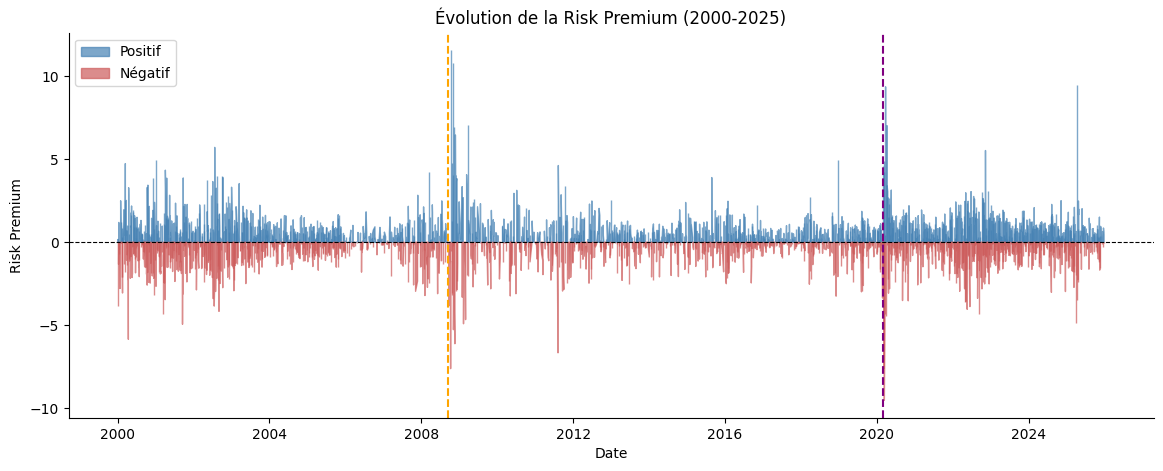

In [12]:
# Evolution du Risk Premium dans le temps
fig, ax = plt.subplots(figsize=(14, 5))
for condition, color, label in [(df_B['Risk_Premium'] >= 0, 'steelblue', 'Positif'), 
                                 (df_B['Risk_Premium'] < 0, 'indianred', 'Négatif')]:
    ax.fill_between(df_B['date'], df_B['Risk_Premium'], 0, where=condition, color=color, alpha=0.7, label=label)

# Marquage des périodes de forte volatilité
for date, color in [('2008-09-15', 'orange'), ('2020-03-01', 'purple')]:
    ax.axvline(pd.Timestamp(date), color=color, linewidth=1.5, linestyle='--')

ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set(title='Évolution de la Risk Premium (2000-2025)', xlabel='Date', ylabel='Risk Premium')
ax.legend(fontsize=10)
sns.despine()
plt.show()

Au jour le jour, la prime de risque oscille autour de zéro, avec des journées positives et
négatives globalement équilibrées. On observe surtout un fort regroupement de la volatilité autour
de 2008, 2011 et 2020, où les variations extrêmes, à la hausse comme à la baisse, se concentrent.

Avant d'aller plus loin, nous visualisons l'évolution de l'indice de biodiversité sur l'ensemble de la période. Cette étape exploratoire permet d'identifier d'éventuelles tendances ou ruptures dans la série avant toute modélisation.

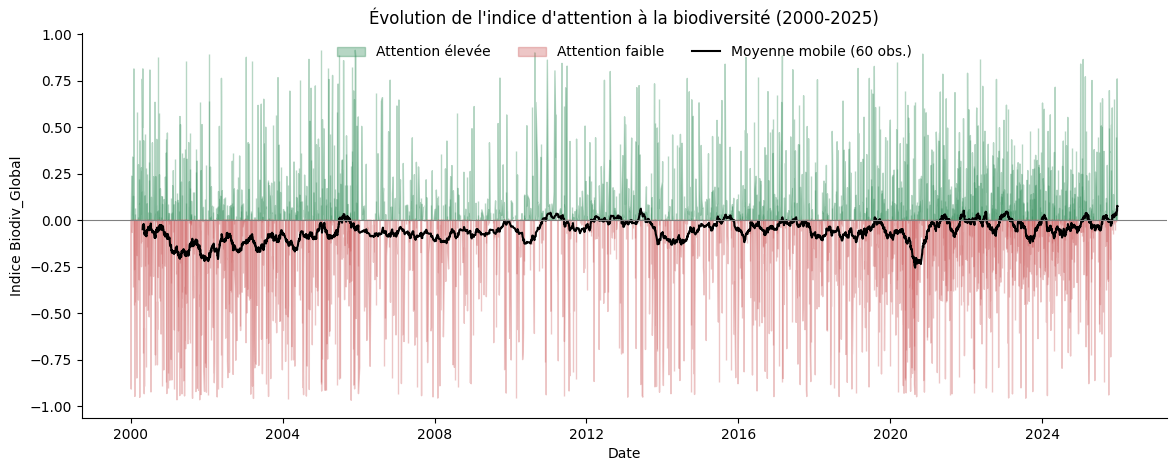

In [13]:
bio = df_B.set_index('date')['Biodiv_Global']
bio_roll = bio.rolling(60).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.fill_between(bio.index, bio, 0, where=bio >= 0, color='seagreen', alpha=0.35, label='Attention élevée')
ax.fill_between(bio.index, bio, 0, where=bio < 0, color='indianred', alpha=0.35, label='Attention faible')
ax.plot(bio_roll.index, bio_roll, color='black', linewidth=1.5, label='Moyenne mobile (60 obs.)')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set(title="Évolution de l'indice d'attention à la biodiversité (2000-2025)",
       xlabel='Date', ylabel='Indice Biodiv_Global')
ax.legend(loc='upper center', ncol=3, frameon=False)
sns.despine()
plt.show()

L'attention portée à la biodiversité dans les médias américains fluctue autour d'une valeur neutre sur toute la période : certaines périodes concentrent davantage d'articles et de couverture sur le sujet, d'autres beaucoup moins, sans qu'aucune tendance durable ne se dessine.

In [14]:
# Exploration initiale des données
df_B.describe()

,date,Mkt-RF,SMB,HML,RMW,CMA,RF,Mom,Biodiv_Global,SP500,Rendement,Risk_Premium
count,4020,4020.000000,4020.000000,4020.000000,4020.000000,4020.000000,4020.000000,4020.000000,4020.000000,4020.000000,4020.000000,4020.000000
mean,2013-11-01 01:55:42.089552,0.044908,0.000716,0.017998,0.021239,0.015828,0.008400,0.011214,-0.058011,2550.331017,0.046819,0.038418
min,2000-01-04 00:00:00,-9.630000,-4.580000,-5.030000,-2.970000,-5.310000,0.000000,-14.370000,-0.968851,696.330000,-9.511268,-9.521268
25%,2005-08-10 12:00:00,-0.490000,-0.370000,-0.350000,-0.290000,-0.230000,0.000000,-0.460000,-0.205346,1227.130000,-0.465166,-0.473884
50%,2015-02-25 00:00:00,0.060000,0.000000,0.000000,0.010000,0.010000,0.010000,0.070000,0.004672,1988.850000,0.058133,0.053557
75%,2021-07-06 06:00:00,0.640000,0.380000,0.370000,0.320000,0.250000,0.020000,0.580000,0.090621,3901.132500,0.613616,0.603247
max,2025-12-26 00:00:00,11.360000,5.710000,6.730000,4.570000,2.470000,0.030000,5.190000,0.913992,6929.940000,11.580036,11.580036
std,NaN,1.217922,0.676160,0.817101,0.590714,0.496649,0.008737,1.097406,0.330813,1580.424516,1.194803,1.194898


In [15]:
# Vérification des valeurs manquantes
df_B.isnull().sum()

date             0
Mkt-RF           0
SMB              0
HML              0
RMW              0
CMA              0
RF               0
Mom              0
Biodiv_Global    0
SP500            0
Rendement        0
Risk_Premium     0
dtype: int64

In [16]:
# Types des colonnes
df_B.dtypes

date             datetime64[us]
Mkt-RF                  float64
SMB                     float64
HML                     float64
RMW                     float64
CMA                     float64
RF                      float64
Mom                     float64
Biodiv_Global           float64
SP500                   float64
Rendement               float64
Risk_Premium            float64
dtype: object

In [17]:
# Suppression des NaN 
df_B = df_B.dropna(subset=['Risk_Premium'])
print("Après nettoyage :", df_B.shape)

Après nettoyage : (4020, 12)


In [18]:
# Vérification des doublons après suppression des NaN
print(f"Nombre de doublons : {df_B.duplicated().sum()}")

Nombre de doublons : 0


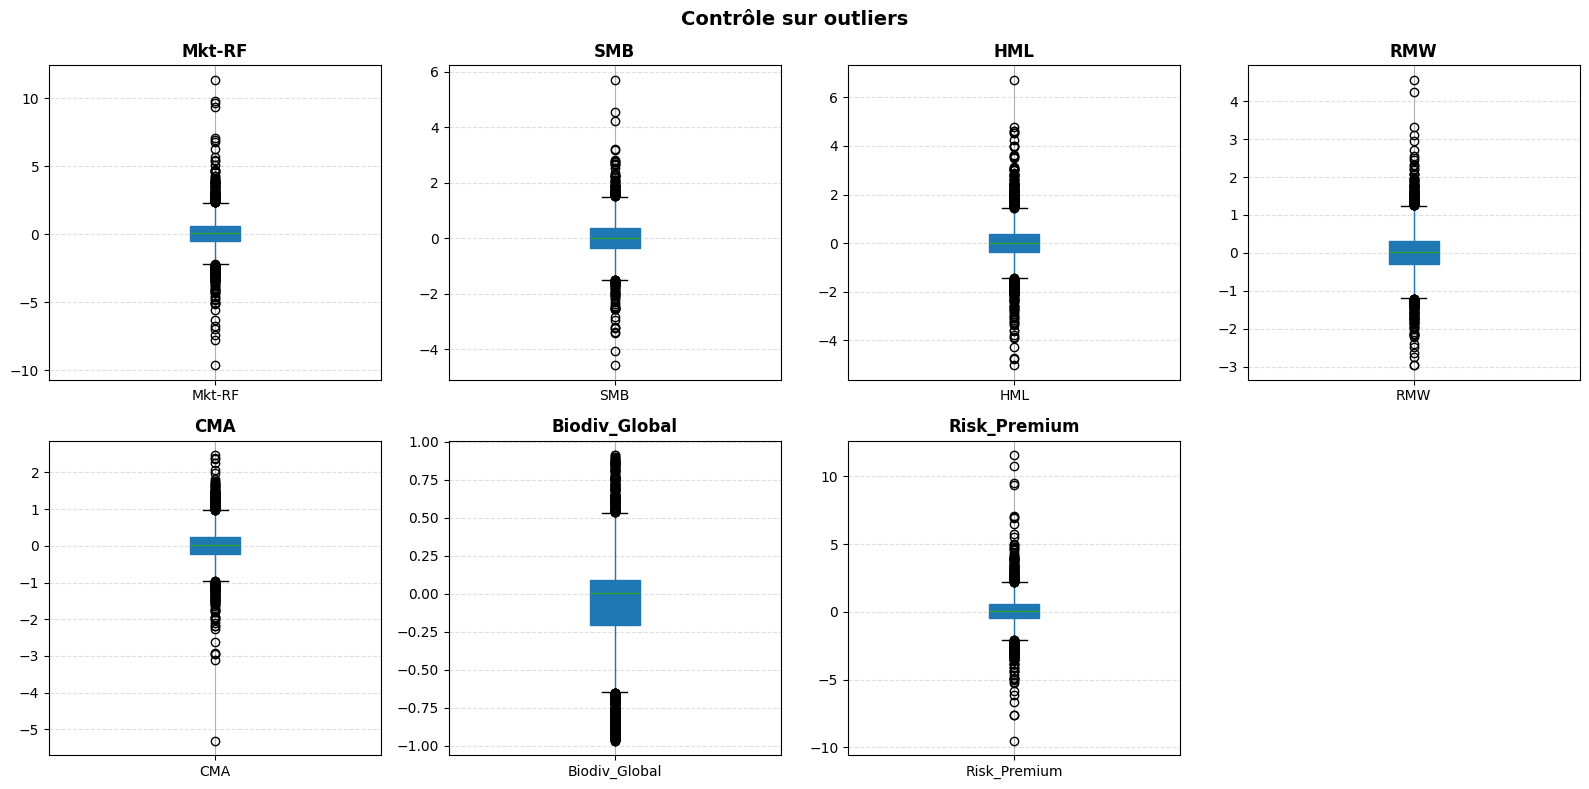

In [19]:
# Contrôle des outliers
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
cols = ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'Biodiv_Global', 'Risk_Premium']

for ax, col in zip(axes.flatten(), cols):
    df_B.boxplot(column=col, ax=ax, patch_artist=True)
    ax.set_title(col, fontweight='bold')
    ax.grid(axis='y', linestyle='--', alpha=0.4)

axes.flatten()[-1].set_visible(False)
fig.suptitle('Contrôle sur outliers', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [20]:
# Distribution des variables et valeurs extrêmes
print("Distribution des variables et valeurs extrêmes :")
print(df_B[cols].agg(['min', 'max', 'std', 'kurt']).round(2))

Distribution des variables et valeurs extrêmes :
      Mkt-RF   SMB   HML   RMW   CMA  Biodiv_Global  Risk_Premium
min    -9.63 -4.58 -5.03 -2.97 -5.31          -0.97         -9.52
max    11.36  5.71  6.73  4.57  2.47           0.91         11.58
std     1.22  0.68  0.82  0.59  0.50           0.33          1.19
kurt    9.13  4.65  5.90  3.97  6.53           0.95         10.41


Au cours de la période étudiée (2000-2025), les marchés financiers ont traversé plusieurs
épisodes de forte volatilité, qui apparaissent dans nos données sous forme de valeurs extrêmes.
Nous les conservons sous leur forme brute, car ils peuvent révéler le comportement du marché en
période de tension, une information de risque au cœur de notre étude.

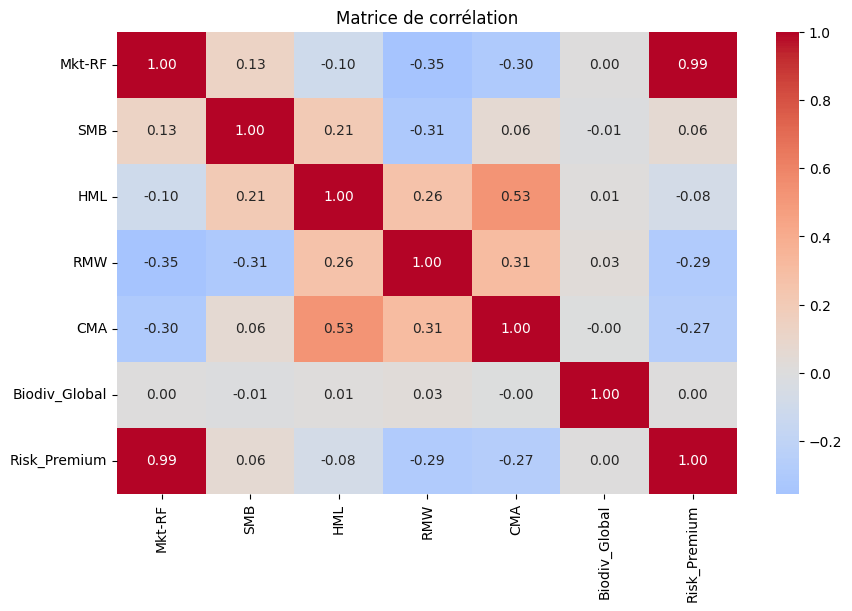

In [21]:
plt.figure(figsize=(10, 6))
sns.heatmap(df_B[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matrice de corrélation')
plt.show()

Le facteur de marché (Mkt-RF) est presque parfaitement corrélé à la prime de risque (0,99), ce qui est
attendu puisque le SP500 représente l'essentiel du marché américain. L'indice de biodiversité en est,
lui, pas corrélé (0,00). Les corrélations entre facteurs restent modérées (max 0,53 entre
HML et CMA), ne signalant pas de multicolinéarité sévère.

# PARTIE A : Modélisation et sélection du modèle

On observe que la corrélation entre l'indice de biodiversité et la prime de risque est nulle (0,00). Ce premier résultat, bien qu'indicatif, ne saurait tenir lieu de conclusion, une corrélation brute ne permettant pas d'isoler l'effet propre d'une variable. C'est pourquoi nous procédons à une modélisation multivariée afin d'établir formellement cet effet en contrôlant les cinq facteurs Fama-French.

#### Choix des modèles:

Quatre modèles seront testés, en deux familles :
- linéaires (simples) : OLS et RidgeCV ;
- non linéaires (complexes) : Random Forest et Gradient Boosting.

Ils seront évalués sur le modèle complet (Fama-French + biodiversité), selon leur R²,
RMSE et MAE, sur un split chronologique (entraînement 2000-2022, test 2022-2025).
L'objectif : voir si un modèle complexe explique mieux la prime de risque, ou si un modèle
simple suffit. Le choix reposera sur la performance et l'interprétabilité
(indispensable pour mesurer l'effet propre de la biodiversité).

In [22]:
# Découpage chronologique 80 / 20 (pas de mélange aléatoire sur une série temporelle)
df_B_sorted = df_B.sort_values('date').reset_index(drop=True)
split_idx = int(len(df_B_sorted) * 0.8)

X = df_B_sorted[['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'Biodiv_Global']]
y = df_B_sorted['Risk_Premium']

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Train : {df_B_sorted['date'].iloc[0].date()} au {df_B_sorted['date'].iloc[split_idx-1].date()} ({split_idx} obs.)")
print(f"Test  : {df_B_sorted['date'].iloc[split_idx].date()} au {df_B_sorted['date'].iloc[-1].date()} ({len(df_B_sorted) - split_idx} obs.)")

Train : 2000-01-04 au 2022-05-23 (3216 obs.)
Test  : 2022-05-24 au 2025-12-26 (804 obs.)


In [23]:
# Table qui stockera les 4 modèles
resultats = []

-----------------------------------------------------------------------------  A.1 Modèle OLS     ----------------------------------------------------------------------------

In [24]:
# --- Modèle OLS ---
ols = LinearRegression()
ols.fit(X_train, y_train)
pred = ols.predict(X_test)

r2 = r2_score(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
mae = mean_absolute_error(y_test, pred)

In [25]:
resultats.append({'Modèle': 'OLS', 'R²': round(r2, 4), 'RMSE': round(rmse, 4), 'MAE': round(mae, 4)})
print(f"Modèle OLS\nR² : {r2:.4f}\nRMSE : {rmse:.4f}\nMAE : {mae:.4f}")

Modèle OLS
R² : 0.9944
RMSE : 0.0787
MAE : 0.0613


-----------------------------------------------------------------------------  A.2 Modèle RidgeCV    --------------------------------------------------------------------------

In [26]:
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 50)))
ridge.fit(X_train, y_train)
pred = ridge.predict(X_test)

In [27]:
r2 = r2_score(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
mae = mean_absolute_error(y_test, pred)

In [28]:
resultats.append({'Modèle': 'RidgeCV', 'R²': round(r2, 4), 'RMSE': round(rmse, 4), 'MAE': round(mae, 4)})
print(f"Modèle RidgeCV\nR² : {r2:.4f}\nRMSE : {rmse:.4f}\nMAE : {mae:.4f}")

Modèle RidgeCV
R² : 0.9944
RMSE : 0.0787
MAE : 0.0613


-----------------------------------------------------------------------------  A.3 Modèle Random Forest    ----------------------------------------------------------------

In [29]:
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)

In [30]:
r2 = r2_score(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
mae = mean_absolute_error(y_test, pred)

In [31]:
resultats.append({'Modèle': 'Random Forest', 'R²': round(r2, 4), 'RMSE': round(rmse, 4), 'MAE': round(mae, 4)})
print(f"Modèle Random Forest\nR² : {r2:.4f}\nRMSE : {rmse:.4f}\nMAE : {mae:.4f}")

Modèle Random Forest
R² : 0.9955
RMSE : 0.0708
MAE : 0.0517


-----------------------------------------------------------------------------  A.4 Modèle Gradient Boosting    ----------------------------------------------------------------

In [32]:
gb = GradientBoostingRegressor(random_state=42)
gb.fit(X_train, y_train)
pred = gb.predict(X_test)

In [33]:
r2 = r2_score(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
mae = mean_absolute_error(y_test, pred)

In [34]:
resultats.append({'Modèle': 'Gradient Boosting', 'R²': round(r2, 4), 'RMSE': round(rmse, 4), 'MAE': round(mae, 4)})
print(f"Modèle Gradient Boosting\nR² : {r2:.4f}\nRMSE : {rmse:.4f}\nMAE : {mae:.4f}")

Modèle Gradient Boosting
R² : 0.9946
RMSE : 0.0776
MAE : 0.0539


-----------------------------------------------------------------------------  A.5 Tableau comparatif    ----------------------------------------------------------------

In [35]:
comp = pd.DataFrame(resultats).set_index('Modèle')
comp

,R²,RMSE,MAE
Modèle,,,
OLS,0.9944,0.0787,0.0613
RidgeCV,0.9944,0.0787,0.0613
Random Forest,0.9955,0.0708,0.0517
Gradient Boosting,0.9946,0.0776,0.0539


Les quatre modèles obtiennent des performances quasiment identiques (R² ≈ 0,99). Le Random Forest arrive
très légèrement en tête (R² = 0,9955 contre 0,9944 pour l'OLS), mais l'écart est négligeable : les modèles
non linéaires n'apportent pas de gain notable, ce qui confirme une relation essentiellement linéaire
entre les facteurs et la prime de risque.

Test de stationnarité (ADF) : nous privilégions donc un modèle linéaire. Avant de retenir l'OLS, nous vérifions l'une de ses conditions de validité : la stationnarité des séries. Une série non stationnaire (avec tendance permanente) peut produire des coefficients et des p-values erronés : on parle de régression fallacieuse. Le test ADF (Dickey-Fuller augmenté) teste H₀ : la série possède une racine unitaire (non stationnaire). Si la p-value est inférieure à 0,05, la série est stationnaire et cette condition de l'OLS est respectée.

In [36]:
# Test de Dickey-Fuller augmenté (1979) : vérifie que chaque série est stationnaire,
# afin que la relation estimée ne soit pas due à une tendance commune dans le temps.
vars_a_tester = ['Risk_Premium', 'Biodiv_Global', 'Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']

resultats_adf = []
for col in vars_a_tester:
    stat, pval, _, _, _, _ = adfuller(df_B[col].dropna(), autolag='AIC')
    conclusion = 'Stationnaire' if pval < 0.05 else 'Non stationnaire'
    resultats_adf.append({'Variable': col, 'Stat. ADF': round(stat, 3),
                          'p-value': round(pval, 4), 'Conclusion': conclusion})

adf_df = pd.DataFrame(resultats_adf).set_index('Variable')
print(adf_df.to_string())
print("\nSeuil de rejet : p-value < 0,05 -> série stationnaire")

               Stat. ADF  p-value    Conclusion
Variable                                       
Risk_Premium     -17.855      0.0  Stationnaire
Biodiv_Global    -61.449      0.0  Stationnaire
Mkt-RF           -17.937      0.0  Stationnaire
SMB              -62.868      0.0  Stationnaire
HML              -15.082      0.0  Stationnaire
RMW              -27.187      0.0  Stationnaire
CMA              -11.088      0.0  Stationnaire

Seuil de rejet : p-value < 0,05 -> série stationnaire


---------------------------------------------------------------- **Justification du choix du modèle OLS** ------------------------------------------------------------

Sur le split chronologique (entraînement 2000-2022, test 2022-2025), les quatre modèles atteignent un R² d'environ 0,99 : la complexité des modèles non linéaires n'apporte aucun gain réel. Entre les deux modèles linéaires, aux performances identiques, nous retenons l'OLS, seul à produire des coefficients et des p-values directement interprétables, condition nécessaire pour évaluer l'effet de la biodiversité. Le test ADF confirme la validité de ce choix : l'ensemble des séries sont stationnaires (p = 0,000), avec des statistiques largement inférieures au seuil critique de -2,86 (à 5 %), en particulier la prime de risque (stat. ADF = -17,86) et l'indice de biodiversité (stat. ADF = -61,45), écartant ainsi tout risque de régression fallacieuse.

# PARTIE B : Effet de la biodiversité sur la prime de risque 

### Analyse approfondie du modèle retenu (OLS)

Cette analyse approfondie se déroule en deux temps : une approche globale sur l'ensemble de la période
(2000-2025), puis une approche découpée par sous-période pour vérifier la stabilité des
résultats dans le temps.

 -----------------------------------------------------------------------.Approche globale (2000-2025) ------------------------------------------------------------------

Nous estimons le modèle OLS retenu sur l'ensemble de la période (2000-2025), en trois temps :
- d'abord le modèle sans biodiversité (socle Fama-French à 5 facteurs), qui sert de référence ;
- puis le modèle avec biodiversité (FF5 + Biodiv_Global) ;
- enfin, nous comparons les deux modèles afin de déterminer l'apport réel de la biodiversité.

Note méthodologique : Le R² présenté en Partie A (≈ 0,994) est un R² de prédiction hors échantillon, calculé sur le jeu de test chronologique (2022-2025) via sklearn. Le R² ajusté présenté ici (≈ 0,996) est un R² d'ajustement en échantillon complet (2000-2025), estimé par statsmodels pour l'analyse économétrique et l'inférence statistique. Ces deux mesures sont complémentaires et n'évaluent pas la même chose ; leur proximité montre que le modèle est stable dans le temps.

B.1 Estimation du modèle FF5 (5 facteurs) sur toute la période d'étude, avec erreurs robustes HAC

In [37]:
X_ff5 = sm.add_constant(df_B[['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']])
y = df_B['Risk_Premium']
maxlags = int(4 * (len(y) / 100) ** (2/9))
modele_ff5 = sm.OLS(y, X_ff5).fit(cov_type='HAC', cov_kwds={'maxlags': maxlags})

In [38]:
# Tableau des coefficients 
res = pd.DataFrame({
    'Coefficient': modele_ff5.params,
    'Erreur-type': modele_ff5.bse,
    'p-value': modele_ff5.pvalues
})
res['Signif.'] = res['p-value'].apply(lambda p: '***' if p<0.01 else '**' if p<0.05 else '*' if p<0.10 else '')
for col in ['Coefficient', 'Erreur-type', 'p-value']:
    res[col] = res[col].map('{:.4f}'.format)

print(res.to_string())
print(f"\nR² ajusté : {modele_ff5.rsquared_adj:.4f}  |  AIC : {modele_ff5.aic:.1f}")
print("Signif. : *** p<0.01, ** p<0.05, * p<0.10")

       Coefficient Erreur-type p-value Signif.
const      -0.0098      0.0012  0.0000     ***
Mkt-RF      1.0061      0.0025  0.0000     ***
SMB        -0.1237      0.0047  0.0000     ***
HML         0.0273      0.0031  0.0000     ***
RMW         0.0876      0.0076  0.0000     ***
CMA         0.0457      0.0053  0.0000     ***

R² ajusté : 0.9959  |  AIC : -9217.6
Signif. : *** p<0.01, ** p<0.05, * p<0.10


B.2 Estimation du modèle FF5 + biodiversité

In [39]:
X_bio = sm.add_constant(df_B[['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'Biodiv_Global']])
y = df_B['Risk_Premium']
modele_bio = sm.OLS(y, X_bio).fit(cov_type='HAC', cov_kwds={'maxlags': maxlags})

B.3 Comparaison des deux modèles

Le tableau ci-dessous compare les coefficients des deux modèles (avec leur significativité),
ainsi que le R² ajusté et l'AIC.

In [40]:
tableau = summary_col(
    [modele_ff5, modele_bio],
    model_names=['FF5', 'FF5 + biodiversité'],
    stars=True,
    info_dict={'AIC': lambda m: f'{m.aic:.1f}'}
)
print(tableau)
print("\nErreurs-types entre parenthèses. *** p<0,01, ** p<0,05, * p<0,10")


                  FF5     FF5 + biodiversité
--------------------------------------------
const          -0.0098*** -0.0096***        
               (0.0012)   (0.0012)          
Mkt-RF         1.0061***  1.0061***         
               (0.0025)   (0.0025)          
SMB            -0.1237*** -0.1237***        
               (0.0047)   (0.0047)          
HML            0.0273***  0.0273***         
               (0.0031)   (0.0031)          
RMW            0.0876***  0.0876***         
               (0.0076)   (0.0076)          
CMA            0.0457***  0.0457***         
               (0.0053)   (0.0053)          
Biodiv_Global             0.0027            
                          (0.0036)          
R-squared      0.9959     0.9959            
R-squared Adj. 0.9959     0.9959            
AIC            -9217.6    -9216.2           
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01

Erreurs-types entre parenthèses. *** p<0,01, ** p<0,05, * p<0,10


Le marché (Mkt-RF) affiche un coefficient de 1,0061, très significatif et pratiquement égal à 1, ce
qui est attendu puisque la prime du SP500 suit le marché. Le facteur taille (SMB) est négatif et
significatif (orientation vers les grandes capitalisations), tandis que les facteurs valeur (HML),
rentabilité (RMW) et investissement (CMA) sont positifs et significatifs, bien que de faible
amplitude. La constante est légèrement négative (-0,0098 % par jour) et significative : elle
s'explique principalement par le fait que l'indice SP500 utilisé est un indice de prix, hors dividendes,
alors que le facteur de marché Fama-French intègre les dividendes. Les facteurs Fama-French expliquent
ainsi la quasi-totalité de la prime de risque (R² ajusté de 0,9959).

La biodiversité (Biodiv_Global), en revanche, présente un coefficient de 0,0027 avec une p-value
de 0,45 : elle est non significative. Deux éléments le confirment : les cinq facteurs demeurent
strictement identiques entre les deux modèles, et l'AIC se dégrade légèrement (de -9217,6 à -9216,2)
tandis que le R² ajusté reste inchangé (0,9959).

Au-delà des cinq facteurs Fama-French, l'attention portée à la biodiversité n'exerce donc aucun effet
sur la prime de risque du SP500. Nous retenons ce résultat comme la réponse principale de notre étude.

Importance relative des facteurs (coefficients standardisés)

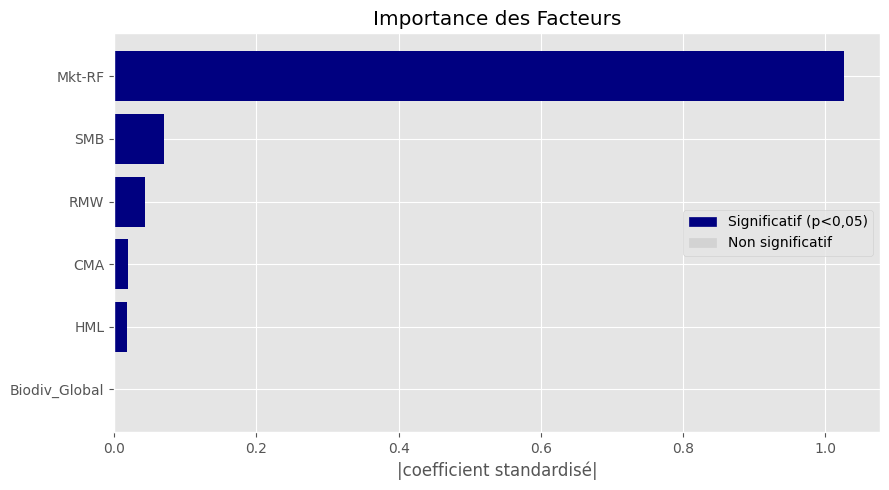

In [41]:
facteurs = ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'Biodiv_Global']
imp = (modele_bio.params[facteurs].abs() * df_B[facteurs].std() / df_B['Risk_Premium'].std()).sort_values()
pvals = modele_bio.pvalues[facteurs][imp.index]
couleurs = ['navy' if pvals[v] < 0.05 else 'lightgray' for v in imp.index]

with plt.style.context('ggplot'):
    plt.figure(figsize=(9, 5))
    plt.barh(imp.index, imp.values, color=couleurs)
    plt.title("Importance des Facteurs")
    plt.xlabel("|coefficient standardisé|")
    plt.legend(handles=[Patch(color='navy', label='Significatif (p<0,05)'),
                        Patch(color='lightgray', label='Non significatif')],
               loc='center right')
    plt.tight_layout()
    plt.show()

Nous utilisons ici les coefficients standardisés (effet d'un écart-type) afin de comparer les
facteurs sur une base commune, car les coefficients bruts ne sont pas comparables entre eux. La couleur
distingue les facteurs significatifs (p<0,05), en bleu, des facteurs non significatifs, en gris.

B.4  Diagnostic : Contrôle du modèle et justification des erreurs robustes

In [42]:
dw = durbin_watson(modele_bio.resid)
bp_stat, bp_pvalue, _, _ = het_breuschpagan(modele_bio.resid, modele_bio.model.exog)

print(f"Durbin-Watson  : {dw:.4f}  -> pas d'autocorrélation")
if bp_pvalue < 0.001:
    print("Breusch-Pagan  : p-value < 0,001  -> hétéroscédasticité détectée")
else:
    print(f"Breusch-Pagan  : p-value = {bp_pvalue:.4f}")

Durbin-Watson  : 2.0360  -> pas d'autocorrélation
Breusch-Pagan  : p-value < 0,001  -> hétéroscédasticité détectée


On constate d'abord que les résidus ne sont pas autocorrélés : le test de Durbin-Watson affiche une
valeur de 2,04, très proche de 2. En revanche, le test de Breusch-Pagan met en évidence une
hétéroscédasticité (p < 0,001), c'est-à-dire une variance des résidus qui n'est pas constante dans le
temps. Ce phénomène étant courant sur les rendements financiers, nous y répondons en retenant des
erreurs-types robustes HAC, afin de garantir la fiabilité de nos p-values.

B.4.1 Test de multicolinéarité (VIF)

In [43]:
# VIF : détection de la multicolinéarité entre variables explicatives
X_vif = df_B[['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'Biodiv_Global']].copy()
vif_df = pd.DataFrame({
    'Variable': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
}).set_index('Variable').round(2)
vif_df['Diagnostic'] = vif_df['VIF'].apply(
    lambda v: 'OK (< 5)' if v < 5 else 'Modéré (5-10)' if v < 10 else 'Problématique (> 10)'
)
print(vif_df.to_string())
print("\nSeuils : VIF < 5 : pas de multicolinéarité | 5-10 : modéré | > 10 : problématique")

                VIF Diagnostic
Variable                      
Mkt-RF         1.21   OK (< 5)
SMB            1.23   OK (< 5)
HML            1.53   OK (< 5)
RMW            1.42   OK (< 5)
CMA            1.54   OK (< 5)
Biodiv_Global  1.00   OK (< 5)

Seuils : VIF < 5 : pas de multicolinéarité | 5-10 : modéré | > 10 : problématique


Les VIF de tous les facteurs sont inférieurs à 5, ce qui confirme l'absence de multicolinéarité problématique entre les variables explicatives. La corrélation de 0,53 observée entre HML et CMA dans la matrice de corrélation ne génère donc pas de redondance susceptible de biaiser les coefficients ou de gonfler les erreurs-types. Le modèle OLS est ainsi validé sur ce point.

---------------------------------------------------------------------------B.5 Conclusion de l'analyse globale--------------------------------------------------------------------

Sur l'ensemble de la période étudiée (2000-2025), on constate que l'attention portée à la biodiversité
n'a aucun effet significatif sur la prime de risque du SP500. Son coefficient n'est pas significatif
(p = 0,45), son ajout ne modifie pas les facteurs Fama-French et n'améliore pas la qualité du modèle
(R² ajusté inchangé, AIC légèrement dégradé). On en retient qu'au-delà des cinq facteurs Fama-French,
la biodiversité n'apporte aucun pouvoir explicatif : au niveau agrégé, elle n'est pas valorisée dans la
prime de risque du marché américain. Ce résultat constitue la réponse principale de notre étude. Dans la
suite de notre projet, nous vérifierons si ce résultat se maintient sur différentes sous-périodes.

B.6 Approche découpée

L'analyse globale a établi que la biodiversité n'exerce aucun effet significatif sur la prime de risque
du SP500. Mais ce constat porte sur vingt-cinq années agrégées en un seul bloc, ce qui pourrait
dissimuler un effet localisé dans le temps. Pour lever cette ambiguïté, nous réestimons le modèle
FF5 + biodiversité sur plusieurs sous-périodes, l'échantillon complet servant de référence.

Notre découpage épouse les grandes phases qui ont rythmé les marchés : la bulle internet et la crise
de 2008 (2000-2009), une décennie de hausse soutenue (2010-2019), puis le choc sanitaire et
l'instabilité qui lui a succédé (2020-2025). En confrontant le modèle à ces environnements contrastés,
nous éprouvons la solidité de notre conclusion.

# PARTIE C : Robustesse sur sous-périodes

In [44]:

# Estimation du modèle FF5 + biodiversité sur chaque sous-période, avec l'échantillon complet comme référence.

periodes = {
    '2000-2009': ('2000-01-01', '2009-12-31'),
    '2010-2019': ('2010-01-01', '2019-12-31'),
    '2020-2025': ('2020-01-01', '2025-12-31'),
    '2000-2025 (référence)': ('2000-01-01', '2025-12-31'),
}
facteurs = ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'Biodiv_Global']

res = []
for nom, (d1, d2) in periodes.items():
    sub = df_B[(df_B['date'] >= d1) & (df_B['date'] <= d2)]
    X = sm.add_constant(sub[facteurs])
    y = sub['Risk_Premium']
    m = sm.OLS(y, X).fit(cov_type='HAC', cov_kwds={'maxlags': int(4*(len(y)/100)**(2/9))})
    res.append({
        'Période': nom,
        'N': int(m.nobs),
        'Coef. biodiversité': round(m.params['Biodiv_Global'], 4),
        'p-value': round(m.pvalues['Biodiv_Global'], 4),
        'R² ajusté': round(m.rsquared_adj, 4),
    })

print(pd.DataFrame(res).to_string(index=False))

              Période    N  Coef. biodiversité  p-value  R² ajusté
            2000-2009 1466             -0.0045   0.4987     0.9954
            2010-2019 1258              0.0007   0.8352     0.9981
            2020-2025 1296              0.0052   0.3825     0.9973
2000-2025 (référence) 4020              0.0027   0.4548     0.9959


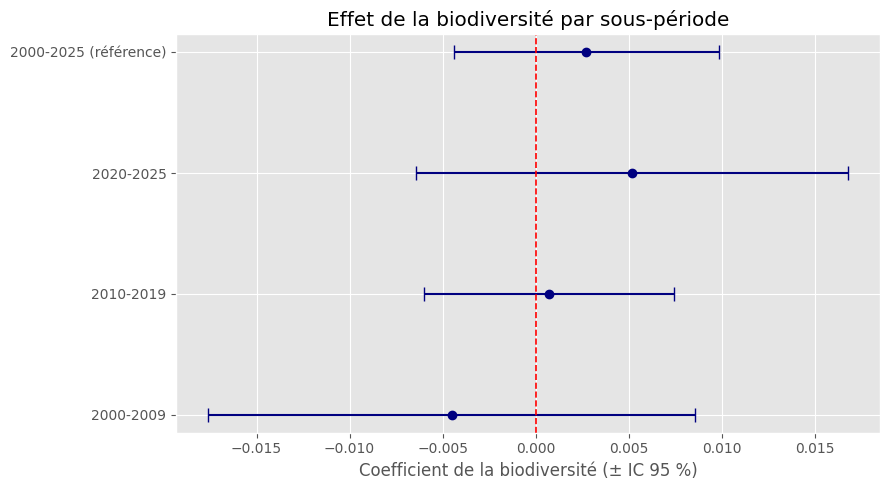

In [45]:
# Graphique : coefficient de la biodiversité par sous-période (± IC 95 %)
coefs, erreurs = [], []
for d1, d2 in periodes.values():
    sub = df_B[(df_B['date'] >= d1) & (df_B['date'] <= d2)]
    m = sm.OLS(sub['Risk_Premium'], sm.add_constant(sub[facteurs])).fit(
        cov_type='HAC', cov_kwds={'maxlags': int(4*(len(sub)/100)**(2/9))})
    coefs.append(m.params['Biodiv_Global'])
    erreurs.append(1.96 * m.bse['Biodiv_Global'])

with plt.style.context('ggplot'):
    plt.figure(figsize=(9, 5))
    plt.errorbar(coefs, range(len(periodes)), xerr=erreurs, fmt='o', capsize=5, color='navy')
    plt.axvline(0, color='red', ls='--', lw=1.2)
    plt.yticks(range(len(periodes)), list(periodes.keys()))
    plt.xlabel("Coefficient de la biodiversité (± IC 95 %)")
    plt.title("Effet de la biodiversité par sous-période")
    plt.tight_layout()
    plt.show()

On constate que le coefficient de la biodiversité reste non significatif sur toutes les sous-périodes
(p-value entre 0,38 et 0,84), ce que confirme le graphique : l'intervalle de confiance traverse la
ligne zéro à chaque fois. Les coefficients sont par ailleurs de très faible amplitude et changent de
signe d'une période à l'autre, signe d'un simple bruit autour de zéro plutôt que d'un effet réel.

Le résultat se vérifie ainsi dans des contextes de marché très différents (crise, hausse prolongée,
instabilité récente), ce qui montre que l'absence d'effet de la biodiversité ne tient pas à une
conjoncture particulière et renforce notre conclusion principale.

# PARTIE D : Biodiversité et risque extrême (Value-at-Risk)

Un facteur peut n'avoir aucun effet sur le rendement moyen tout en modifiant le risque extrême, celui
des pertes rares mais importantes. La Value-at-Risk (VaR) mesure justement ce risque : elle indique la
perte maximale attendue pour un niveau de confiance donné (une VaR à 95 % de -3 % signifie que la perte
journalière ne dépasse pas 3 % dans 95 % des cas). Nous mesurons d'abord ce risque extrême sur la prime
de risque du SP500, puis nous testons si la biodiversité l'influence à l'aide d'une régression quantile.

D.1 Value-at-Risk et Expected Shortfall de la prime de risque

In [46]:
# VaR historique : quantile de la distribution de la prime de risque
# Expected Shortfall (CVaR) : perte moyenne au-delà de la VaR
rp = df_B['Risk_Premium']
for niveau in (0.95, 0.99):
    var = rp.quantile(1 - niveau)
    cvar = rp[rp <= var].mean()
    print(f"Seuil {niveau:.0%}  |  VaR : {var:.2f} %   CVaR : {cvar:.2f} %")

Seuil 95%  |  VaR : -1.83 %   CVaR : -2.76 %
Seuil 99%  |  VaR : -3.17 %   CVaR : -4.45 %


Dans 5 % des cas, la perte journalière dépasse 1,83 % (VaR 95 %), et dans 1 % des cas elle dépasse
3,17 % (VaR 99 %). Nous complétons la VaR par l'Expected Shortfall (CVaR), qui mesure la perte moyenne
au-delà du seuil de VaR : lorsque ces seuils sont franchis, la perte moyenne atteint 2,76 % (95 %) et
4,45 % (99 %). Cette mesure est consacrée par le cadre réglementaire de Bâle III, qui l'a retenue comme
mesure de référence du risque de marché en remplacement de la VaR.

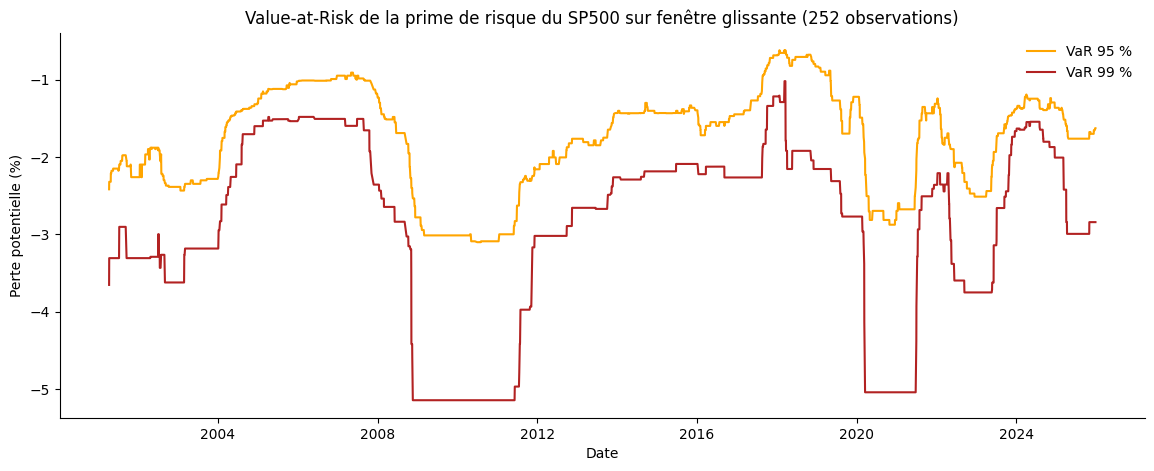

In [47]:
var95 = df_B['Risk_Premium'].rolling(252).quantile(0.05)
var99 = df_B['Risk_Premium'].rolling(252).quantile(0.01)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_B['date'], var95, color='orange', linewidth=1.5, label='VaR 95 %')
ax.plot(df_B['date'], var99, color='firebrick', linewidth=1.5, label='VaR 99 %')
ax.set(title="Value-at-Risk de la prime de risque du SP500 sur fenêtre glissante (252 observations)",
       xlabel='Date', ylabel='Perte potentielle (%)')
ax.legend(frameon=False)
sns.despine()
plt.show()

On observe que le risque extrême du SP500 varie fortement dans le temps. En période calme (par exemple
2017-2019), la VaR à 95 % est d'environ -1 % : dans 95 % des cas, la perte journalière ne dépasse pas 1 %.
Mais lors des crises, ce risque s'envole : pendant la crise financière de 2008, la VaR à 99 % atteint
environ -5,1 %, autrement dit le marché pouvait perdre plus de 5 % en une seule journée dans les cas
extrêmes. On retrouve un pic comparable lors du choc de 2020 (environ -5,0 %).

Ce profil montre que les pertes extrêmes ne se répartissent pas uniformément : elles se concentrent sur
quelques épisodes de tension. C'est la traduction visuelle de l'hétéroscédasticité (variance non
constante) déjà détectée par le test de Breusch-Pagan.

D.2 Distribution de la prime de risque et seuils de VaR

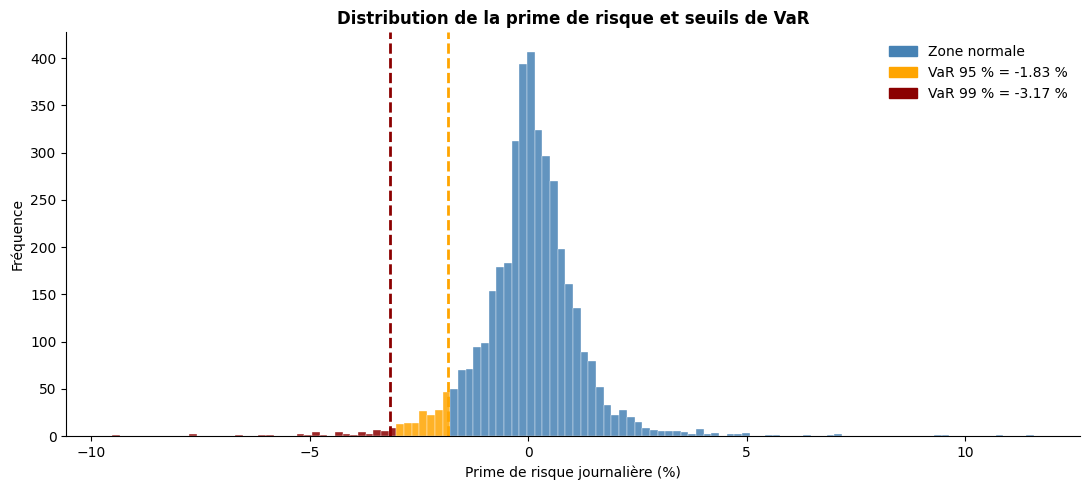

In [48]:
var95, var99 = rp.quantile(0.05), rp.quantile(0.01)

fig, ax = plt.subplots(figsize=(11, 5))
counts, bins, patches = ax.hist(rp, bins=120, edgecolor='white', linewidth=0.3, alpha=0.85)
for p, left in zip(patches, bins[:-1]):
    p.set_facecolor('darkred' if left < var99 else 'orange' if left < var95 else 'steelblue')

ax.axvline(var95, color='orange', lw=2, ls='--')
ax.axvline(var99, color='darkred', lw=2, ls='--')
ax.set_title("Distribution de la prime de risque et seuils de VaR", fontweight='bold')
ax.set_xlabel("Prime de risque journalière (%)"); ax.set_ylabel("Fréquence")
ax.spines[['top','right']].set_visible(False)
ax.legend(handles=[Patch(color='steelblue', label='Zone normale'),
                   Patch(color='orange', label=f'VaR 95 % = {var95:.2f} %'),
                   Patch(color='darkred', label=f'VaR 99 % = {var99:.2f} %')], frameon=False)
plt.tight_layout()
plt.show()

On observe que la prime de risque se concentre autour de zéro, avec des queues marquées de part et
d'autre. Les seuils de VaR délimitent la zone des pertes extrêmes : dans 5 % des cas la perte
journalière dépasse 1,83 % (VaR 95 %), et dans 1 % des cas elle dépasse 3,17 % (VaR 99 %). La présence
de ces queues épaisses confirme que le risque ne suit pas une loi normale.

D.3 Risque extrême par sous-période

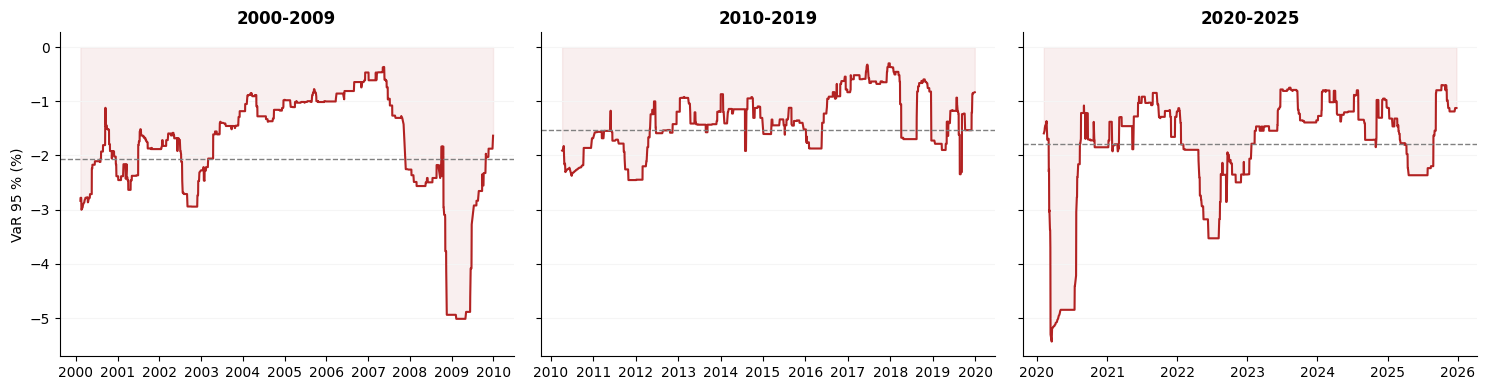

In [49]:
periodes_var = {'2000-2009': ('2000-01-01','2009-12-31'),
                '2010-2019': ('2010-01-01','2019-12-31'),
                '2020-2025': ('2020-01-01','2025-12-31')}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (nom, (d1, d2)) in zip(axes, periodes_var.items()):
    sub = df_B[(df_B['date'] >= d1) & (df_B['date'] <= d2)]
    var95 = sub['Risk_Premium'].rolling(63, min_periods=20).quantile(0.05)
    ax.fill_between(pd.to_datetime(sub['date']), var95, 0, color='firebrick', alpha=0.07)
    ax.plot(pd.to_datetime(sub['date']), var95, color='firebrick', lw=1.5)
    ax.axhline(sub['Risk_Premium'].quantile(0.05), color='gray', ls='--', lw=1)
    ax.set_title(nom, fontweight='bold')
    ax.spines[['top','right']].set_visible(False)
    ax.grid(True, axis='y', color='whitesmoke')

axes[0].set_ylabel("VaR 95 % (%)")
plt.tight_layout()
plt.show()

On constate que le risque extrême varie nettement selon les périodes. La période 2000-2009 présente le
risque le plus élevé sur l'ensemble de la décennie (VaR 95 % de -2,07 %), avec un pic à environ -5 % lors
de la crise de 2008. La décennie 2010-2019 apparaît au contraire la plus calme, avec un risque stable et
modéré (VaR 95 % de -1,53 %). Enfin, 2020-2025 se distingue par un choc bref mais très violent en 2020
(pic à environ -5,4 %), suivi d'un retour rapide à la normale (VaR 95 % de -1,79 %).

D.4 Effet de la biodiversité sur le risque extrême : régression quantile

La régression OLS mesure l'effet de la biodiversité sur la prime de risque moyenne. Pour savoir si
elle influence les pertes extrêmes, nous utilisons une régression quantile, qui estime l'effet des
variables sur un quantile donné de la distribution, ici les quantiles 5 % et 1 %, c'est-à-dire
précisément les seuils de VaR. Nous estimons la biodiversité seule, puis avec les cinq facteurs
Fama-French.

In [50]:
X_seule = sm.add_constant(df_B[['Biodiv_Global']])
X_ff5_bio = sm.add_constant(df_B[facteurs])

res_q = []
for q in (0.05, 0.01):
    for nom, X in [('Biodiversité seule', X_seule), ('FF5 + biodiversité', X_ff5_bio)]:
        m = sm.QuantReg(df_B['Risk_Premium'], X).fit(q=q)
        res_q.append({'Quantile': f'{q:.0%}', 'Modèle': nom,
                      'Coef. biodiversité': round(m.params['Biodiv_Global'], 4),
                      'p-value': round(m.pvalues['Biodiv_Global'], 4)})

print(pd.DataFrame(res_q).to_string(index=False))

Quantile             Modèle  Coef. biodiversité  p-value
      5% Biodiversité seule              0.4021   0.0109
      5% FF5 + biodiversité              0.0015   0.8632
      1% Biodiversité seule              0.5644   0.0888
      1% FF5 + biodiversité             -0.0014   0.9288


Prise seule, la biodiversité semble liée aux pertes extrêmes : au quantile 5 %, son coefficient est
positif et significatif (+0,40 ; p = 0,011), et il l'est faiblement au quantile 1 % (p = 0,089). Mais
cet effet disparaît dès que l'on contrôle par les facteurs Fama-French : le coefficient devient quasi
nul aux deux seuils (p = 0,86 et p = 0,93). Le lien apparent ne relève donc pas d'un effet propre de la
biodiversité, mais d'une coïncidence avec les mouvements du marché. La biodiversité ne modifie ainsi
pas plus le risque extrême du SP500 que sa prime de risque moyenne.

Au regard de cet effet non significatif, une question se pose : une période plus exposée à un événement biodiversité majeur produirait-elle, elle aussi, un effet neutre ? Pour le tester, nous nous penchons sur la COP15. 

---------------------------------------------- Effet de la biodiversité autour d'un événement majeur (COP15)----------------------------------------------------

1. Définition de l'événement (COP15)

In [51]:
COP15 = '2022-12-19'
df_B['Post_COP15'] = (df_B['date'] >= COP15).astype(int)

n_avant = int((df_B['Post_COP15'] == 0).sum())
n_apres = int((df_B['Post_COP15'] == 1).sum())
part_apres = n_apres / len(df_B) * 100

print(f"Période d'étude   : {df_B['date'].min():%d/%m/%Y} au {df_B['date'].max():%d/%m/%Y}")
print(f"Avant COP15       : {n_avant:>5} observations")
print(f"Après COP15       : {n_apres:>5} observations   ({part_apres:.1f} % de l'échantillon)")

Période d'étude   : 04/01/2000 au 26/12/2025
Avant COP15       :  3353 observations
Après COP15       :   667 observations   (16.6 % de l'échantillon)


L'échantillon post-COP15 compte 667 observations, soit 16,6 % de l'échantillon.

2. Effet de la biodiversité avant / après COP15

In [52]:
facteurs = ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'Biodiv_Global']
resultats_cop = []

for periode, subset in [('Avant COP15', df_B[df_B['Post_COP15'] == 0]),
                         ('Après COP15', df_B[df_B['Post_COP15'] == 1])]:
    m = sm.OLS(subset['Risk_Premium'], sm.add_constant(subset[facteurs])).fit(
        cov_type='HAC', cov_kwds={'maxlags': int(4*(len(subset)/100)**(2/9))})
    p = m.pvalues['Biodiv_Global']
    sig = 'Non significatif' if p >= .10 else 'Significatif à 10 %' if p >= .05 else 'Significatif à 5 %'
    coef_str = f"{m.params['Biodiv_Global']:.4f}{'***' if p<.01 else '**' if p<.05 else '*' if p<.10 else ''}"
    resultats_cop.append([periode, int(m.nobs), coef_str, round(p, 4), sig])

t = pd.DataFrame(resultats_cop,
                 columns=['Période', 'N', 'Coef. biodiversité', 'p-value', 'Significativité'])
print(t.to_string(index=False))
print('* p<0,10   ** p<0,05   *** p<0,01')

    Période    N Coef. biodiversité  p-value  Significativité
Avant COP15 3353             0.0015   0.7072 Non significatif
Après COP15  667             0.0054   0.3050 Non significatif
* p<0,10   ** p<0,05   *** p<0,01


Avant la COP15, la biodiversité ne montre aucun effet sur la prime de risque : son coefficient est quasi nul (0,0015) et non significatif (p = 0,7072). Après la COP15, le coefficient reste faible (0,0054) et non significatif (p = 0,3050). L'événement ne semble donc pas modifier le rôle de la biodiversité. Pour le vérifier formellement, nous ajoutons un terme d'interaction (biodiversité × période post-COP15), qui teste si l'effet de la biodiversité diffère entre les deux périodes.

3. Test d'interaction : l'effet de la biodiversité change-t-il après la COP15 ?

In [53]:
d = df_B.copy()
d['Bio_x_Post'] = d['Biodiv_Global'] * d['Post_COP15']    # effet de la biodiversité APRÈS la COP15
X = sm.add_constant(d[facteurs + ['Post_COP15', 'Bio_x_Post']])
m = sm.OLS(d['Risk_Premium'], X).fit(
    cov_type='HAC', cov_kwds={'maxlags': int(4 * (len(d) / 100) ** (2/9))})

print(f"Interaction (Bio × Post-COP15) : {m.params['Bio_x_Post']:.4f}")
print(f"p-value                        : {m.pvalues['Bio_x_Post']:.4f}")

Interaction (Bio × Post-COP15) : 0.0015
p-value                        : 0.8711


Le coefficient d'interaction est quasi nul (+0,0015), avec une p-value de 0,8711 (bien au-dessus de 0,05) : l'effet de la biodiversité ne change pas après la COP15.
Pour vérifier que ce résultat ne dépend pas du choix de la date, nous le comparons à 200 dates de rupture fictives : si beaucoup produisent un coefficient aussi élevé en valeur absolue que la vraie COP15, c'est que celui-ci se confond avec le bruit.

4. Test placebo : vrai signal COP15 contre 200 fausses dates tirées au hasard

In [54]:
def interaction_coef(date_r):
    d = df_B.assign(Post=(df_B['date'] >= pd.Timestamp(date_r)).astype(int))
    d['Bio_x_Post'] = d['Biodiv_Global'] * d['Post']
    if min(d['Post'].sum(), (1 - d['Post']).sum()) < 200:
        return None
    return sm.OLS(d['Risk_Premium'], sm.add_constant(d[facteurs + ['Post', 'Bio_x_Post']])).fit(
        cov_type='HAC', cov_kwds={'maxlags': int(4 * (len(d) / 100) ** (2/9))}).params['Bio_x_Post']

coef_vrai = interaction_coef('2022-12-19')
rng = np.random.default_rng(0)
faux = rng.choice(df_B['date'].iloc[300:-300].values, 200, replace=False)
placebo = pd.Series([c for d in faux if (c := interaction_coef(pd.Timestamp(d))) is not None])
part = (placebo.abs() >= abs(coef_vrai)).mean() * 100

print(f"Vrai coefficient COP15 : {coef_vrai:+.4f}")
print(f"Placebos aussi grands (ou plus) : {part:.0f}%")

Vrai coefficient COP15 : +0.0015
Placebos aussi grands (ou plus) : 76%


Le test placebo confirme l'absence d'effet propre à l'événement : 76 % des dates fictives produisent un coefficient aussi élevé en valeur absolue, voire plus, que la vraie COP15 (résultat stable, identique à chaque exécution du test). Le coefficient observé autour de la COP15 se confond avec le bruit : il ressemble à ce que produirait n'importe quelle date tirée au hasard.

5. Figure de synthèse COP15 

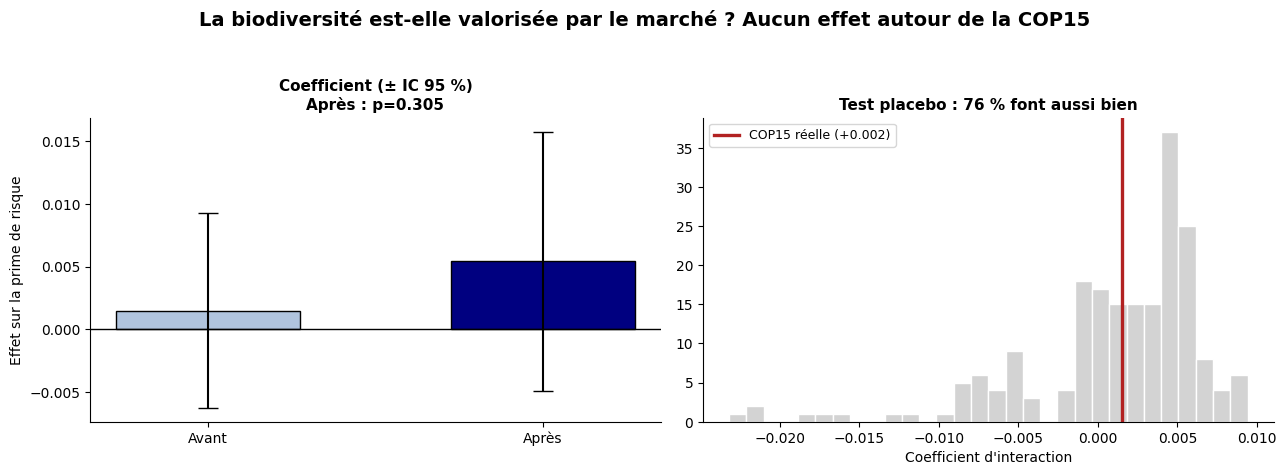

In [55]:
def modele_hac(X, y):
    maxlags_val = int(4*(len(y)/100)**(2/9))
    return sm.OLS(y, X).fit(cov_type='HAC', cov_kwds={'maxlags': maxlags_val})

cs, es, ps = [], [], []
for k in (0, 1):
    sub = df_B[df_B['Post_COP15'] == k]
    m = modele_hac(sm.add_constant(sub[facteurs]), sub['Risk_Premium'])
    cs.append(m.params['Biodiv_Global'])
    es.append(1.96 * m.bse['Biodiv_Global'])
    ps.append(m.pvalues['Biodiv_Global'])

# coef_vrai, placebo et part proviennent du test placebo ci-dessus
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
fig.suptitle("La biodiversité est-elle valorisée par le marché ? Aucun effet autour de la COP15",
             fontsize=14, fontweight='bold', color='black')

ax[0].bar([0, 1], cs, width=.55, color=['lightsteelblue', 'navy'], edgecolor='black')
ax[0].errorbar([0, 1], cs, yerr=es, fmt='none', ecolor='black', capsize=7)
ax[0].axhline(0, color='black', lw=1)
ax[0].set_xticks([0, 1])
ax[0].set_xticklabels(['Avant', 'Après'])
ax[0].set_title(f"Coefficient (± IC 95 %)\nAprès : p={ps[1]:.3f}", fontsize=11, fontweight='bold')
ax[0].set_ylabel("Effet sur la prime de risque")

ax[1].hist(placebo, bins=30, color='lightgray', edgecolor='white')
ax[1].axvline(coef_vrai, color='firebrick', lw=2.4, label=f"COP15 réelle ({coef_vrai:+.3f})")
ax[1].set_title(f"Test placebo : {part:.0f} % font aussi bien", fontsize=11, fontweight='bold')
ax[1].set_xlabel("Coefficient d'interaction")
ax[1].legend(fontsize=9)

for a in ax:
    a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

-------------------------------------------------------------------------CONCLUSION GÉNÉRALE--------------------------------------------------------------------------

Cette étude ne met en évidence aucun effet statistiquement significatif de l’attention portée à la biodiversité sur la prime de risque du marché américain, aussi bien sur l’ensemble de la période étudiée que lors des épisodes de risque extrême ou autour de la COP15.

Ces résultats suggèrent que les risques liés à la biodiversité ne sont pas encore clairement intégrés dans la formation de la prime de risque du S&P 500, dont les variations restent principalement expliquées par les facteurs traditionnels de Fama-French.

Toutefois, l’évolution des cadres réglementaires, des données environnementales et des pratiques financières pourrait progressivement renforcer la prise en compte de ces risques par les marchés.

-------------------------------------------------------------------Limites et perspectives--------------------------------------------------------------------------------

Cette étude présente plusieurs limites. L’utilisation de données agrégées du S&P 500 ne permet pas d’identifier les effets propres aux secteurs ou aux entreprises particulièrement exposés aux risques de biodiversité. Par ailleurs, l’indice d’attention médiatique mesure les préoccupations liées à la biodiversité sans nécessairement refléter leur matérialisation financière, tandis que sa couverture temporelle limite le nombre d’observations disponibles.

La période relativement courte suivant la COP15, ainsi que la présence d’autres facteurs macroéconomiques, peuvent également affecter la portée des résultats. Ces limites ouvrent des perspectives de recherche fondées sur des analyses sectorielles, des données individuelles d’entreprises et un horizon d’observation plus long, à mesure que les dispositifs réglementaires et de reporting sur la biodiversité se développent.